# 01 - Exploratory data analysis (Olist Brazilian E-Commerce)

Purpose: understand shape, coverage and quality of the real dataset **before** trusting any KPI, and justify the modelling rules used in `sql/`.
Everything here is computed from `data/raw/` (not committed; see `data/raw/README.md`) by running the project's own SQL models, so notebook and pipeline cannot disagree.
Descriptive only: no causal claims. Currency is as recorded in the data (not stated in the dataset; presumably BRL).

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import duckdb, pandas as pd, matplotlib.pyplot as plt
from src import config
from src.transformation.run_sql import build_models

pd.options.display.float_format = "{:,.3f}".format
con = duckdb.connect(":memory:")
build_models(con, config.DATA_RAW)
q = lambda sql: con.execute(sql).df()

## 1. Table sizes and keys

In [2]:
tables = ["clean_orders", "clean_customers", "clean_order_items", "clean_payments", "clean_reviews", "clean_products", "clean_sellers"]
pd.DataFrame({"rows": [con.execute(f"select count(*) from {t}").fetchone()[0] for t in tables]}, index=tables)

,rows
clean_orders,99441
clean_customers,99441
clean_order_items,112650
clean_payments,103886
clean_reviews,99224
clean_products,32951
clean_sellers,3095


In [3]:
q("""select count(*) orders, count(distinct order_id) distinct_orders,
          (select count(distinct customer_unique_id) from clean_customers) unique_customers,
          (select count(*) from clean_customers) customer_ids
   from clean_orders""")

,orders,distinct_orders,unique_customers,customer_ids
0,99441,99441,96096,99441


`customer_id` is one-per-order in this dataset; `customer_unique_id` identifies the person, so repeat-purchase analysis must use `customer_unique_id`.

## 2. Time coverage - which months can be trusted?

In [4]:
cov = q("select purchase_month, count(*) orders from fact_orders group by 1 order by 1")
print(cov.head(6).to_string(index=False)); print("...");print(cov.tail(3).to_string(index=False))
print("min/max purchase:", *con.execute("select min(purchase_ts), max(purchase_ts) from fact_orders").fetchone())

purchase_month  orders
    2016-09-01       4
    2016-10-01     324
    2016-12-01       1
    2017-01-01     800
    2017-02-01    1780
    2017-03-01    2682
...
purchase_month  orders
    2018-08-01    6512
    2018-09-01      16
    2018-10-01       4
min/max purchase: 2016-09-04 21:15:19 2018-10-17 17:30:18


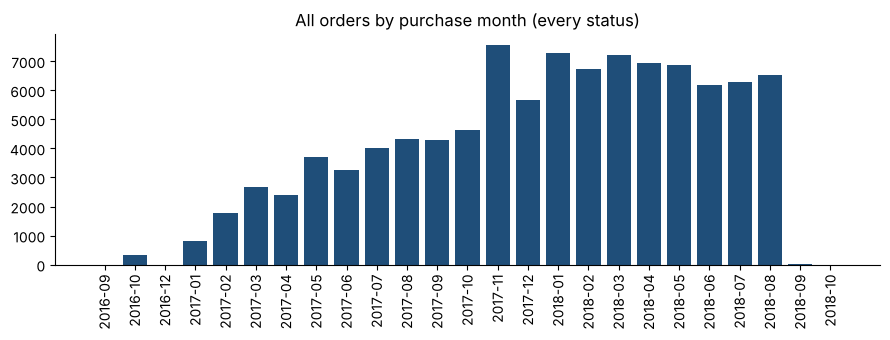

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(cov["purchase_month"].astype(str).str[:7], cov["orders"], color="#1f4e79")
ax.set_title("All orders by purchase month (every status)"); ax.tick_params(axis="x", rotation=90)
ax.spines[["top", "right"]].set_visible(False); plt.tight_layout(); plt.show()

Sep-Dec 2016 hold only a handful of orders (and Nov 2016 has none) and Sep-Oct 2018 are partial, so trend comparisons use full calendar months only (Jan-Aug 2017 vs Jan-Aug 2018).

## 3. Order status

In [6]:
q("select order_status, count(*) orders, count(*)*1.0/sum(count(*)) over () as order_share from fact_orders group by 1 order by 2 desc")

,order_status,orders,order_share
0,delivered,96478,0.970
1,shipped,1107,0.011
2,canceled,625,0.006
3,unavailable,609,0.006
4,invoiced,314,0.003
5,processing,301,0.003
6,created,5,0.000
7,approved,2,0.000


## 4. Missing values that affect KPI denominators

In [7]:
q("""select
  count(*) orders,
  count(*) filter (where item_count is null) no_items,
  count(*) filter (where payment_value is null) no_payment,
  count(*) filter (where review_score is null) no_review,
  count(*) filter (where order_status='delivered' and delivered_ts is null) delivered_without_ts,
  count(*) filter (where delivery_eligible) delivery_eligible
from fact_orders""")

,orders,no_items,no_payment,no_review,delivered_without_ts,delivery_eligible
0,99441,775,1,768,8,96470


In [8]:
q("select order_status, count(*) orders_without_items from fact_orders where item_count is null group by 1 order by 2 desc")

,order_status,orders_without_items
0,unavailable,603
1,canceled,164
2,created,5
3,invoiced,2
4,shipped,1


Orders without items are almost all `unavailable`/`canceled`, which is why they are excluded from sales and AOV. Delivered orders lacking a delivery timestamp are **not** counted as on time.

## 5. Item price and freight distribution

                    count    mean     std   min    50%     90%     99%       max
price         112,650.000 120.654 183.634 0.850 74.990 229.800 890.000 6,735.000
freight_value 112,650.000  19.990  15.806 0.000 16.260  34.041  84.520   409.680


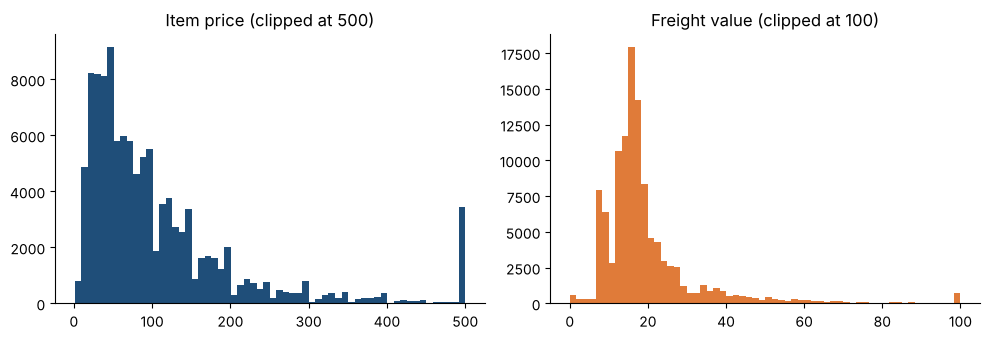

In [9]:
items = q("select price, freight_value from clean_order_items")
print(items.describe(percentiles=[.5, .9, .99]).T.to_string())
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(items["price"].clip(upper=500), bins=60, color="#1f4e79"); axes[0].set_title("Item price (clipped at 500)")
axes[1].hist(items["freight_value"].clip(upper=100), bins=60, color="#e07b39"); axes[1].set_title("Freight value (clipped at 100)")
for a in axes: a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

Heavily right-skewed, so medians and bands are reported next to averages.

## 6. Order grain: why items/payments/reviews are aggregated before joining

In [10]:
q("""select
 (select count(*) from clean_order_items) item_rows,
 (select count(distinct order_id) from clean_order_items) orders_with_items,
 (select count(*) - count(distinct order_id) from clean_payments) extra_payment_rows,
 (select count(*) - count(distinct order_id) from clean_reviews) extra_review_rows""")

,item_rows,orders_with_items,extra_payment_rows,extra_review_rows
0,112650,98666,4446,551


In [11]:
# Demonstration: a naive orders x items x payments join inflates product value
naive = con.execute("""select sum(i.price) from clean_orders o
   join clean_order_items i using(order_id) join clean_payments p using(order_id)""").fetchone()[0]
correct = con.execute("select sum(product_value) from fact_orders").fetchone()[0]
print(f"naive join: {naive:,.2f}   order-grain model: {correct:,.2f}   inflation: {naive/correct-1:.1%}")

naive join: 14,209,115.34   order-grain model: 13,591,643.70   inflation: 4.5%


## 7. Delivery time and lateness

count   96,470.000
mean        12.558
std          9.546
min          0.533
50%         10.217
90%         23.096
99%         46.050
max        209.629
late rate: 0.0811 | eligible orders: 96470


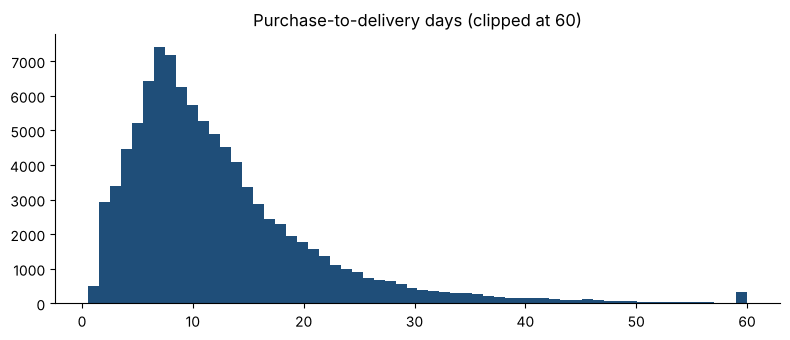

In [12]:
d = q("select delivery_days, is_late from fact_orders where delivery_eligible")
print(d["delivery_days"].describe(percentiles=[.5, .9, .99]).to_string())
print("late rate:", round(d["is_late"].mean(), 4), "| eligible orders:", len(d))
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(d["delivery_days"].clip(upper=60), bins=60, color="#1f4e79"); ax.set_title("Purchase-to-delivery days (clipped at 60)")
ax.spines[["top", "right"]].set_visible(False); plt.tight_layout(); plt.show()

## 8. Review scores and the late-delivery association

In [13]:
r = q("select review_score, count(*) orders from fact_orders where review_score is not null group by 1 order by 1")
r["share"] = r["orders"] / r["orders"].sum(); r

,review_score,orders,share
0,1,11365,0.115
1,2,3130,0.032
2,3,8135,0.082
3,4,19044,0.193
4,5,56999,0.578


In [14]:
q("""select case when is_late then 'late' else 'on_time' end delivery_outcome, review_score, count(*) orders
   from fact_orders where delivery_eligible and review_score is not null group by 1,2 order by 1,2""")\
  .pivot(index="review_score", columns="delivery_outcome", values="orders").assign(
      late_share=lambda t: t["late"] / t["late"].sum(), on_time_share=lambda t: t["on_time"] / t["on_time"].sum())

delivery_outcome,late,on_time,late_share,on_time_share
review_score,,,,
1,3541,5811,0.462,0.066
2,600,2320,0.078,0.026
3,872,7046,0.114,0.080
4,944,17950,0.123,0.204
5,1704,55036,0.222,0.624


Late orders skew heavily toward low scores. This is an **association**: reviews are voluntary and late orders may differ in region, category or seller, so it does not show that lateness causes the lower scores.

## 9. Payments

In [15]:
q("select payment_type, count(*) records, sum(payment_value) as total_payment_value, avg(payment_installments) avg_installments from clean_payments group by 1 order by 2 desc")

,payment_type,records,total_payment_value,avg_installments
0,credit_card,76795,"12,542,084.190",3.507
1,boleto,19784,"2,869,361.270",1.000
2,voucher,5775,"379,436.870",1.000
3,debit_card,1529,"217,989.790",1.000
4,not_defined,3,0.000,1.000


In [16]:
# Payment value vs product value + freight (they need not match: vouchers, installment interest)
q("""select count(*) orders,
   count(*) filter (where abs(payment_value - (product_value + freight_value)) <= 0.05) matches_within_5c,
   count(*) filter (where abs(payment_value - (product_value + freight_value)) > 0.05) differs
  from fact_orders where payment_value is not null and product_value is not null""")

,orders,matches_within_5c,differs
0,98665,98405,260


## 10. Categories

In [17]:
cat = q("select category, count(*) items, sum(price) as product_sales_value from fact_order_items where order_status not in ('canceled','unavailable') group by 1 order by 3 desc")
cat["share"] = cat["product_sales_value"] / cat["product_sales_value"].sum(); cat["cum_share"] = cat["share"].cumsum()
print("categories:", len(cat)); cat.head(10)

categories: 74


,category,items,product_sales_value,share,cum_share
0,health_beauty,9634,"1,255,695.130",0.093,0.093
1,watches_gifts,5970,"1,198,185.210",0.089,0.182
2,bed_bath_table,11097,"1,035,964.060",0.077,0.259
3,sports_leisure,8590,"979,740.920",0.073,0.331
4,computers_accessories,7781,"904,322.020",0.067,0.398
5,furniture_decor,8298,"727,465.050",0.054,0.452
6,housewares,6915,"626,825.800",0.046,0.499
7,cool_stuff,3779,"620,770.490",0.046,0.545
8,auto,4204,"586,585.730",0.043,0.588
9,garden_tools,4328,"481,009.940",0.036,0.624


## Takeaways that shaped the models
- Use `customer_unique_id` for repeat behaviour; `customer_id` is per order.
- Pre-aggregate items/payments/reviews to order grain (section 6 shows the inflation otherwise).
- Delivery KPIs need an explicit eligible population (section 4/7); missing timestamps are never "on time".
- Only Jan-2017 to Aug-2018 are full months (section 2); trend statements are limited to that window.
- Distributions are skewed (sections 5, 7) - report medians/bands, not just means.